# Data verzamelen
Eerst weer libraries installeren en data inlezen:

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from sklearn.linear_model import LinearRegression
from pandas.plotting import scatter_matrix
from datetime import date
from sklearn.decomposition import KernelPCA

#Clear output
from google.colab import output
output.clear()

Alle libraries geinstalleerd, nu de data:

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2023,5,1)

De grondstoffen en indicatoren:

In [ ]:
inflatie = web.get_data_fred('T10YIE', start, end) #inflatie
rente = web.get_data_fred('FEDFUNDS', start, end) #rente

graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Grondstoffen en Indicatoren in aparte portfolio's zetten:

In [ ]:
indicatoren = pd.concat([rente, inflatie], axis=1)
indicatoren.columns = ["Rente", "Inflatie"]

grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen, hout, katoen, rubber, wol, zonnebloem, uranium], axis=1)
grondstoffen_1.columns = ["Close_Graan", "Close_Koffie", "Close_Vlees", "Close_Gas", "Close_Kolen", "Close_Hout", "Close_Katoen", "Close_Rubber", "Close_Wol", "Close_Zonnebloem", "Close_Uranium"]

grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Close_Olie", "Close_Goud", "Close_Palladium"]

Portfolio-data inlezen:

In [ ]:
apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
nans_gevuld = portfolio_gefilterd.ffill()
nans_gevuld.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]
nans_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,42.275002,69.050003,307.220001,38.930000,54.560001,67.333748,236.669998,102.639999,9119.009766,0.841407
2018-05-02,44.142502,69.180000,307.160004,37.750000,55.020000,67.956764,234.050003,102.589996,9235.919922,0.859094
2018-05-03,44.222500,69.610001,315.679993,38.099998,55.459999,66.758652,233.410004,102.580002,9743.860352,0.884466
2018-05-04,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9700.759766,0.895442
2018-05-05,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2023-04-26,163.759995,60.490002,449.089996,82.250000,62.939999,76.783722,336.559998,92.889999,28422.701172,0.462037
2023-04-27,168.410004,60.680000,457.679993,83.669998,63.700001,78.260178,341.600006,92.660004,29473.787109,0.466868
2023-04-28,169.679993,61.980000,461.269989,84.300003,63.990002,78.986435,343.440002,93.120003,29340.261719,0.480271


We willen ook graag koersdata van de S&P500 index:

In [ ]:
index = yf.download('^GSPC', start, end).tz_localize(None)
index = index.loc[:,["Close"]]
index.columns = ["Close_S&P"]
index

[*********************100%***********************]  1 of 1 completed


,Close_S&P
Date,
2018-05-01,2654.800049
2018-05-02,2635.669922
2018-05-03,2629.729980
2018-05-04,2663.419922
2018-05-07,2672.629883
...,...
2023-04-24,4137.040039
2023-04-25,4071.629883
2023-04-26,4055.989990


# Moving Average
Eens kijken of we ' moving averages' kunnen berekenen van (bijv) de S&P 500 en in een grafiek zetten:

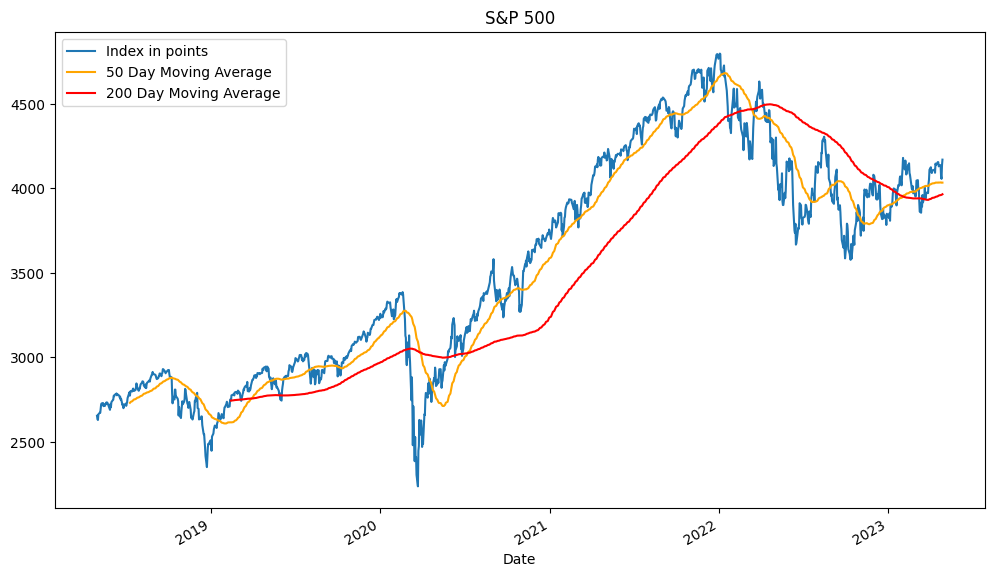

In [ ]:
index["Close_S&P"].plot(figsize = (12,7), label='Index in points')

index['50 Day Moving Average'] = index["Close_S&P"].rolling(50).mean()
index['50 Day Moving Average'].plot(color="orange")

index['200 Day Moving Average'] = index["Close_S&P"].rolling(200).mean()
index['200 Day Moving Average'].plot(color="red")

plt.title('S&P 500')
plt.legend()

Zelfde lopende gemiddeldes, maar nu voor goud:

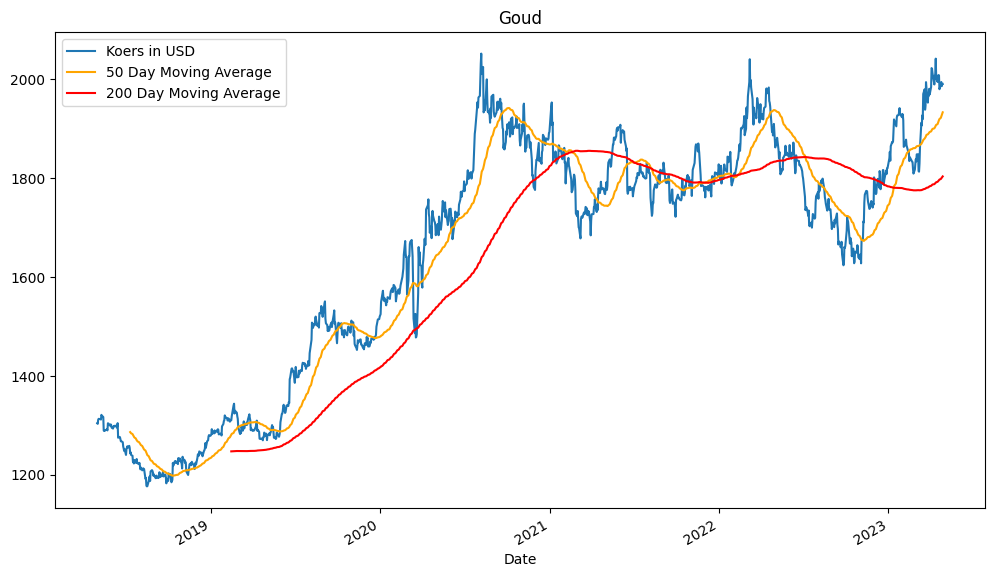

In [ ]:
grondstoffen_2["Close_Goud"].plot(figsize = (12,7), label='Koers in USD')

grondstoffen_2['50 Day Moving Average'] = grondstoffen_2["Close_Goud"].rolling(50).mean()
grondstoffen_2['50 Day Moving Average'].plot(color="orange")

grondstoffen_2['200 Day Moving Average'] = grondstoffen_2["Close_Goud"].rolling(200).mean()
grondstoffen_2['200 Day Moving Average'].plot(color="red")

plt.title('Goud')
plt.legend()

Technische Analyse: leuk om eens terug te kijken, maar als voorspeller .. het lijkt of je altijd achter de trend aanloopt?

# Scatter Matrix
Ook aardig om even te bekijken: is er verband tussen de stand van de index en de koers van bijv olie?

[*********************100%***********************]  1 of 1 completed


array([[<Axes: xlabel='Olie', ylabel='Olie'>,
        <Axes: xlabel='S&P500', ylabel='Olie'>],
       [<Axes: xlabel='Olie', ylabel='S&P500'>,
        <Axes: xlabel='S&P500', ylabel='S&P500'>]], dtype=object)

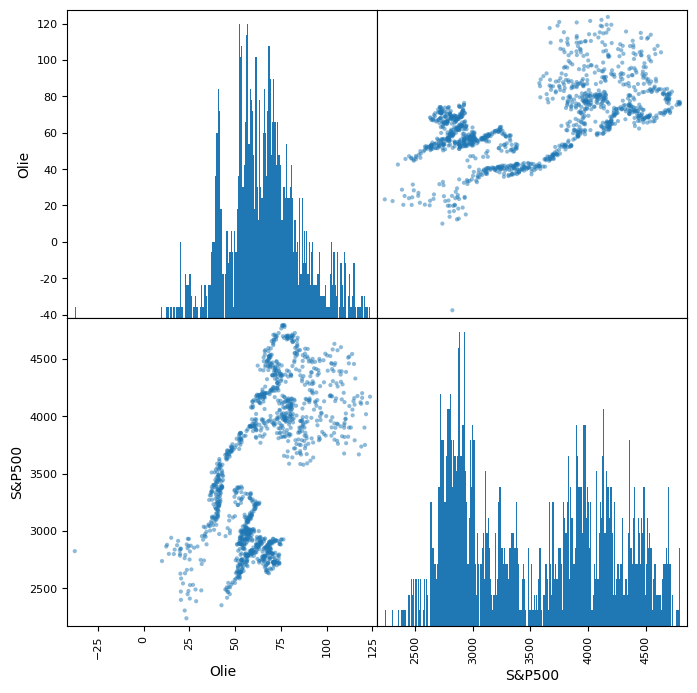

In [ ]:
index = yf.download('^GSPC', start, end).tz_localize(None)
index = index.loc[:,["Close"]]

olie = oil.loc[:,["Close"]]

data = pd.concat([olie,index] ,axis = 1)

data.columns = ['Olie','S&P500']
scatter_matrix(data, figsize = (8,8), hist_kwds= {'bins':250})

Uit het plaatje blijkt dat er een mogelijk verband is tussen de koers van de S&P 500 en de koers van olie: hoe hoger de koers van olie, hoe hoger de stand van de S&P (of andersom?)<br>
<p>
NB: je moet deze analyse natuurlijk eigenlijk maken met (dag)koersrendementen, maar op deze manier zijn de plaatjes mooier ..  

# Principal Component Analysis
Wat is PCA:<br>
A linear technique for dimensionality reduction is Principal Component Analysis (PCA). As its name suggests, PCA breaks down the movement of portfolio asset prices into its principal components, or common factors, for further statistical analysis. Common factors that don't explain much of the movement of the portfolio assets receive less weighting in their factors and are usually ignored. By keeping the most useful factors, portfolio analysis can be greatly simplified without compromising on computational time and space costs.<br>

In slecht Nederlands:<br>
Kunnen we uit een bak met mogelijke verklarende variabelen/factoren alleen die variabelen/factoren selecteren die ook echt een voorspellende waarde hebben?

We gaan een poging doen om de stand van de S&P 500 te verklaren uit de eerder ingelezen macro-economische indicatoren.

In [ ]:
start = dt.datetime(2022,1,1)
end = dt.datetime(2022,12,31)

symbols_fred = ['T10YIE','FEDFUNDS','PWHEAMTUSDM','PCOPPUSDM','WPU026301','WPU08','PBEEFUSDM','PSUNOUSDM','PWOOLFUSDM','PCOTTINDUSDM','PRUBBUSDM']
symbols_yahoo = ['CL=F','GC=F']

macro=pd.DataFrame()
for sym in symbols_yahoo:
  macro[sym] = yf.download(sym, start, end).tz_localize(None)['Close']
macro=macro.dropna()
macro

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


,CL=F,GC=F
Date,,
2022-01-03,76.080002,1799.400024
2022-01-04,76.989998,1814.000000
2022-01-05,77.849998,1824.599976
2022-01-06,79.459999,1788.699951
2022-01-07,78.900002,1797.000000
...,...,...
2022-12-23,79.559998,1795.900024
2022-12-27,79.529999,1814.800049
2022-12-28,78.959999,1807.900024


In [ ]:
macro1 = macro.rename(columns={"CL=F": "olie", "GC=F": "goud"})
macro1

,olie,goud
Date,,
2022-01-03,76.080002,1799.400024
2022-01-04,76.989998,1814.000000
2022-01-05,77.849998,1824.599976
2022-01-06,79.459999,1788.699951
2022-01-07,78.900002,1797.000000
...,...,...
2022-12-23,79.559998,1795.900024
2022-12-27,79.529999,1814.800049
2022-12-28,78.959999,1807.900024


<Axes: xlabel='Date'>

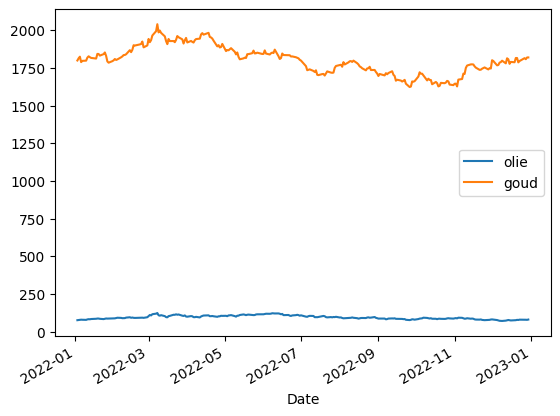

In [ ]:
macro1.plot()

In [ ]:
index = yf.download('^GSPC', start, end).tz_localize(None)
index = index.loc[:,["Close"]]
index.columns = ["Close_S&P"]
index

[*********************100%***********************]  1 of 1 completed


,Close_S&P
Date,
2022-01-03,4796.560059
2022-01-04,4793.540039
2022-01-05,4700.580078
2022-01-06,4696.049805
2022-01-07,4677.029785
...,...
2022-12-23,3844.820068
2022-12-27,3829.250000
2022-12-28,3783.219971


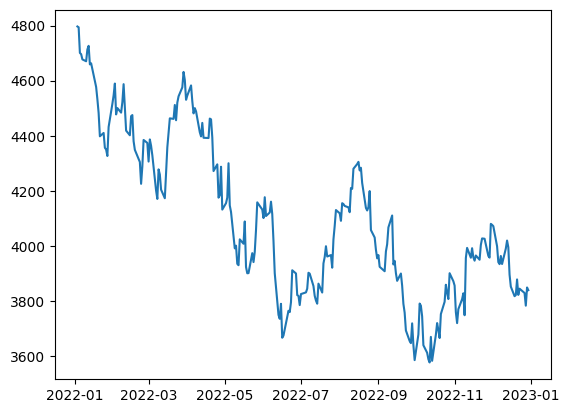

In [ ]:
plt.plot(index)

En nu de PCA: we normaliseren de data met een ' scale function' en passen de PCA toe.

In [ ]:
scale_function = lambda x: (x - x.mean())/x.std()
pca = KernelPCA().fit(macro1.apply(scale_function))

Het gewicht van iedere component wordt berekend door de Eigenwaarde. Er zijn er 2:

In [ ]:
#len(pca.lambdas_)
len(pca.eigenvalues_)

2

In [ ]:
pca.eigenvalues_

array([384.92647235, 115.07352765])

We zijn geinteresseerd in het relatieve gewicht van iedere component, dus gaan we opnieuw normaliseren:

In [ ]:
get_we = lambda x: x / x.sum()
get_we(pca.eigenvalues_)

array([0.76985294, 0.23014706])

De eerste component (olie?) heeft het meeste gewicht, daarna component 2 (goud?). Gezamenlijk (in dit voorbeeld) verklaren zij 100% van de variatie:

In [ ]:
get_we(pca.eigenvalues_)[:2].sum()

1.0

Nu gaan we kijken of we de stand van de S&P 500 kunnen voorspellen op basis van de 1e component:

In [ ]:
pca = KernelPCA(n_components=1).fit(macro1.apply(scale_function))
index['PCA_1'] = pca.transform(macro1)

In [ ]:
df = pd.DataFrame(index['PCA_1'], columns=['PCA_1'])
df

,PCA_1
Date,
2022-01-03,1326.164645
2022-01-04,1337.131851
2022-01-05,1345.235278
2022-01-06,1320.988569
2022-01-07,1326.461612
...,...
2022-12-23,1326.150499
2022-12-27,1339.493622
2022-12-28,1334.211518


<Axes: xlabel='Date'>

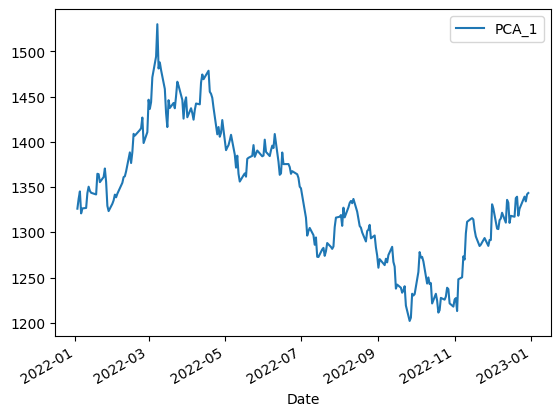

In [ ]:
df.plot()

[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Date'>

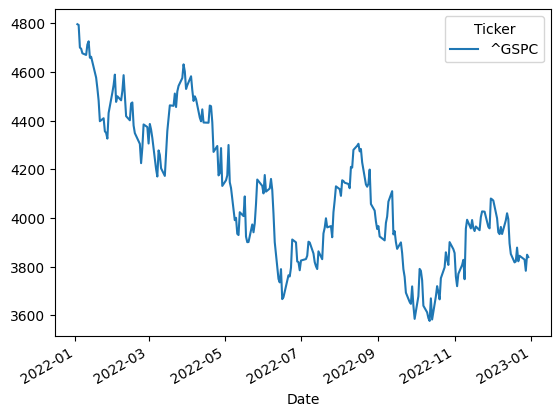

In [ ]:
index = yf.download('^GSPC', start, end).tz_localize(None)['Close']
index.plot()

Vergelijk de beide grafieken, wat is de conclusie?

# Het voorbeeld uit het boek van Python for Finance van Yves Hilpisch

In [ ]:
assets = ["JCI", "TGT", "CMCSA", "CPB", "MO", "APA", "MMC", "JPM",
          "ZION", "PSA", "BAX", "BMY", "LUV", "PCAR", "TXT", "TMO",
          "DE", "MSFT", "HPQ", "SEE", "VZ", "CNP", "NI", "T", "BA","^GSPC"]

data=pd.DataFrame()
for sym in assets:
  data[sym] = yf.download(sym, start, end).tz_localize(None)['Close']
data=data.dropna()
data

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%********

,JCI,TGT,CMCSA,CPB,MO,APA,MMC,JPM,ZION,PSA,...,DE,MSFT,HPQ,SEE,VZ,CNP,NI,T,BA,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2022-01-03,79.349998,231.949997,50.740002,43.740002,47.970001,28.059999,167.229996,161.699997,64.239998,365.279999,...,350.109985,334.750000,38.020000,66.570000,52.439999,27.620001,27.520000,19.206949,207.860001,4796.560059
2022-01-04,80.339996,234.169998,50.189999,44.119999,49.029999,29.459999,167.149994,167.830002,66.070000,365.029999,...,371.290009,329.010010,39.200001,66.940002,53.470001,27.450001,27.620001,19.365559,213.630005,4793.540039
2022-01-05,79.029999,228.860001,50.220001,44.279999,48.639999,28.400000,164.830002,163.779999,66.220001,361.769989,...,372.049988,316.380005,38.869999,66.800003,54.020000,27.389999,27.770000,19.796074,213.070007,4700.580078
2022-01-06,80.379997,231.350006,50.509998,45.029999,49.209999,29.620001,166.690002,165.520004,68.940002,365.339996,...,376.359985,313.880005,38.680000,66.639999,53.759998,27.650000,27.650000,19.720545,211.339996,4696.049805
2022-01-07,79.269997,230.779999,50.049999,45.849998,49.770000,29.670000,163.809998,167.160004,70.089996,355.910004,...,378.649994,314.040009,38.650002,65.699997,54.240002,27.660000,27.870001,19.856495,215.500000,4677.029785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-23,64.099998,143.149994,35.139999,57.279999,46.240002,47.250000,165.589996,131.279999,48.450001,283.209991,...,436.929993,238.729996,26.760000,49.959999,38.410000,30.690001,27.709999,18.309999,189.059998,3844.820068
2022-12-27,64.300003,145.550003,35.000000,57.549999,46.480000,47.639999,166.440002,131.740005,48.840000,283.040009,...,436.149994,236.960007,27.070000,50.060001,39.250000,30.920000,27.799999,18.459999,189.399994,3829.250000
2022-12-28,63.220001,145.800003,34.619999,57.040001,45.849998,45.180000,164.600006,132.460007,47.970001,277.989990,...,430.179993,234.529999,26.540001,48.990002,38.810001,30.520000,27.549999,18.219999,188.380005,3783.219971


In [ ]:
senp = pd.DataFrame(data.pop('^GSPC'))
senp

,^GSPC
Date,
2022-01-03,4796.560059
2022-01-04,4793.540039
2022-01-05,4700.580078
2022-01-06,4696.049805
2022-01-07,4677.029785
...,...
2022-12-23,3844.820068
2022-12-27,3829.250000
2022-12-28,3783.219971


<Axes: xlabel='Date'>

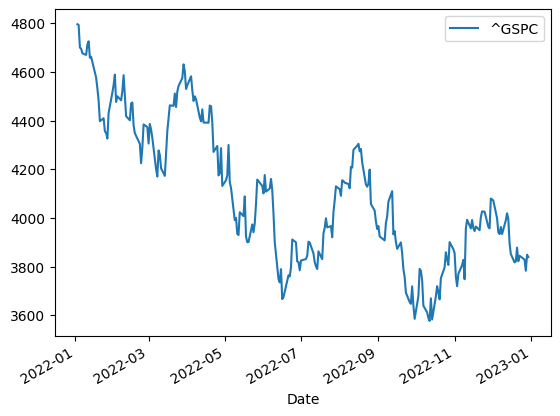

In [ ]:
senp.plot()

In [ ]:
scale_function = lambda x: (x - x.mean())/x.std()
pca = KernelPCA().fit(data.apply(scale_function))

In [ ]:
len(pca.eigenvalues_)

25

In [ ]:
pca.eigenvalues_

array([3.08468649e+03, 1.12543445e+03, 8.13286169e+02, 4.04428651e+02,
       3.19226415e+02, 1.04655551e+02, 7.69513663e+01, 6.08019641e+01,
       4.97365241e+01, 4.54467969e+01, 2.67523044e+01, 2.48625900e+01,
       2.03988958e+01, 1.99083160e+01, 1.51732254e+01, 1.17409225e+01,
       9.19149155e+00, 8.53198165e+00, 7.14576611e+00, 5.77571146e+00,
       4.93420624e+00, 3.71194643e+00, 3.02953575e+00, 2.47428457e+00,
       1.71444753e+00])

In [ ]:
get_we = lambda x: x / x.sum()
get_we(pca.eigenvalues_).round(3)

array([0.494, 0.18 , 0.13 , 0.065, 0.051, 0.017, 0.012, 0.01 , 0.008,
       0.007, 0.004, 0.004, 0.003, 0.003, 0.002, 0.002, 0.001, 0.001,
       0.001, 0.001, 0.001, 0.001, 0.   , 0.   , 0.   ])

In [ ]:
get_we(pca.eigenvalues_)[:5].sum()

0.9195299475822359

In [ ]:
pca = KernelPCA(n_components=1).fit(data.apply(scale_function))
index['PCA_1'] = pca.transform(data)

In [ ]:
#index.apply(scale_function).plot(figsize=(8,4))

In [ ]:
df = pd.DataFrame(index['PCA_1'], columns=['PCA_1'])
df

,PCA_1
Date,
2022-01-03,594.372128
2022-01-04,593.256728
2022-01-05,586.259733
2022-01-06,588.325149
2022-01-07,584.869601
...,...
2022-12-23,458.847910
2022-12-27,460.150651
2022-12-28,455.966374


<Axes: xlabel='Date'>

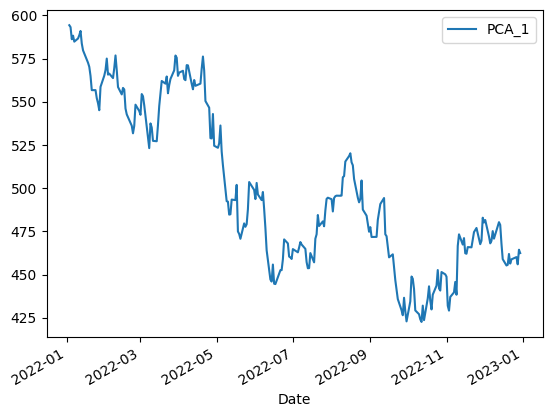

In [ ]:
df.plot()

<Axes: xlabel='Date'>

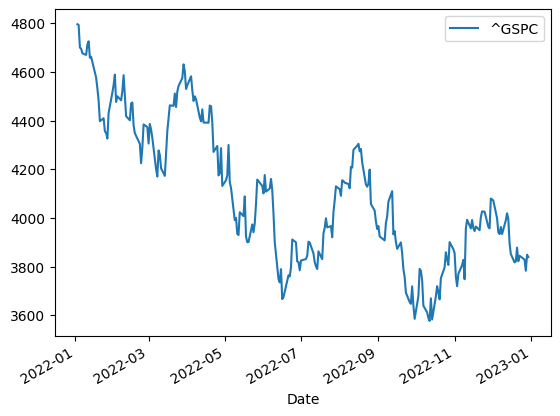

In [ ]:
senp.plot()

Conclusie: het volgen van de trend gaat heel aardig, maar grote uitschieters (zie bijvoorbeeld maart 2020) zijn lastig.

Grote Vraag: hoe weet ik nu wat er in mijn (1e, 2e etc) component zit? Welke variabelen?<br>
<br>
Misschien staat hier het antwoord:<br>
https://online.stat.psu.edu/stat505/lesson/11

# Stock Market Analytics with PCA
Stock Market Analytics with PCA: https://github.com/gylx/Financial-Machine-Learning-Articles<br>

Artikel met uitleg van de onderstaande stappen:<br>
https://medium.com/towards-data-science/stock-market-analytics-with-pca-d1c2318e3f0e

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import bs4 as bs
import requests

In [ ]:
plt.style.use('fivethirtyeight')

In [ ]:
# Scrap sp500 tickers
def save_sp500_tickers():

    resp = requests.get('http://en.wikipedia.org/wiki/List_of_S%26P_500_companies')
    soup = bs.BeautifulSoup(resp.text, 'html')
    table = soup.find('table', {'class': 'wikitable sortable'})
    tickers = []
    for row in table.findAll('tr')[1:]:
        tds = row.findAll('td')
        # Check if the row has enough <td> elements
        if len(tds) > 0:
            ticker = tds[0].text
            if not '.' in ticker:
                tickers.append(ticker.replace('\n',''))

    return tickers

tickers = save_sp500_tickers()

In [ ]:
tickers

['MMM',
 'AOS',
 'ABT',
 'ABBV',
 'ACN',
 'ATVI',
 'ADM',
 'ADBE',
 'ADP',
 'AAP',
 'AES',
 'AFL',
 'A',
 'APD',
 'AKAM',
 'ALK',
 'ALB',
 'ARE',
 'ALGN',
 'ALLE',
 'LNT',
 'ALL',
 'GOOGL',
 'GOOG',
 'MO',
 'AMZN',
 'AMCR',
 'AMD',
 'AEE',
 'AAL',
 'AEP',
 'AXP',
 'AIG',
 'AMT',
 'AWK',
 'AMP',
 'ABC',
 'AME',
 'AMGN',
 'APH',
 'ADI',
 'ANSS',
 'AON',
 'APA',
 'AAPL',
 'AMAT',
 'APTV',
 'ACGL',
 'ANET',
 'AJG',
 'AIZ',
 'T',
 'ATO',
 'ADSK',
 'AZO',
 'AVB',
 'AVY',
 'AXON',
 'BKR',
 'BALL',
 'BAC',
 'BBWI',
 'BAX',
 'BDX',
 'WRB',
 'BBY',
 'BIO',
 'TECH',
 'BIIB',
 'BLK',
 'BK',
 'BA',
 'BKNG',
 'BWA',
 'BXP',
 'BSX',
 'BMY',
 'AVGO',
 'BR',
 'BRO',
 'BG',
 'CHRW',
 'CDNS',
 'CZR',
 'CPT',
 'CPB',
 'COF',
 'CAH',
 'KMX',
 'CCL',
 'CARR',
 'CTLT',
 'CAT',
 'CBOE',
 'CBRE',
 'CDW',
 'CE',
 'CNC',
 'CNP',
 'CDAY',
 'CF',
 'CRL',
 'SCHW',
 'CHTR',
 'CVX',
 'CMG',
 'CB',
 'CHD',
 'CI',
 'CINF',
 'CTAS',
 'CSCO',
 'C',
 'CFG',
 'CLX',
 'CME',
 'CMS',
 'KO',
 'CTSH',
 'CL',
 'CMCSA',
 'CMA',


In [ ]:
import yfinance as yf

def check_valid_tickers(tickers):
  """Checks if a list of tickers contains only valid ticker symbols.

  Args:
    tickers: A list of ticker symbols.

  Returns:
    A list of invalid ticker symbols.
  """
  invalid_tickers = []
  for ticker in tickers:
    try:
      # Try to download some data for the ticker.
      # If it fails, it's likely an invalid ticker.
      yf.download(ticker, period="1d")
    except:
      invalid_tickers.append(ticker)
  return invalid_tickers

In [ ]:
tickers = ['MMM',
 'AOS',
 'ABT',
 'ABBV',
 'ACN',
 'ATVI',
 'ADM',
 'ADBE',
 'ADP',
 'AAP',
 'AES',
 'AFL',
 'A',
 'APD',
 'AKAM',
 'ALK',
 'ALB',
 'ARE',
 'ALGN',
 'ALLE',
 'LNT',
 'ALL',
 'GOOGL',
 'GOOG',
 'MO',
 'AMZN',
 'AMCR',
 'AMD',
 'AEE',
 'AAL',
 'AEP',
 'AXP',
 'AIG',
 'AMT',
 'AWK',
 'AMP',
 'ABC',
 'AME',
 'AMGN',
 'APH',
 'ADI',
 'ANSS',
 'AON',
 'APA',
 'AAPL',
 'AMAT',
 'APTV',
 'ACGL',
 'ANET',
 'AJG',
 'AIZ',
 'T',
 'ATO',
 'ADSK',
 'AZO',
 'AVB',
 'AVY',
 'AXON',
 'BKR',
 'BALL',
 'BAC',
 'BBWI',
 'BAX',
 'BDX',
 'WRB',
 'BBY',
 'BIO',
 'TECH',
 'BIIB',
 'BLK',
 'BK',
 'BA',
 'BKNG',
 'BWA',
 'BXP',
 'BSX',
 'BMY',
 'AVGO',
 'BR',
 'BRO',
 'BG',
 'CHRW',
 'CDNS',
 'CZR',
 'CPT',
 'CPB',
 'COF',
 'CAH',
 'KMX',
 'CCL',
 'CARR',
 'CTLT',
 'CAT',
 'CBOE',
 'CBRE',
 'CDW',
 'CE',
 'CNC',
 'CNP',
 'CDAY',
 'CF',
 'CRL',
 'SCHW',
 'CHTR',
 'CVX',
 'CMG',
 'CB',
 'CHD',
 'CI',
 'CINF',
 'CTAS',
 'CSCO',
 'C',
 'CFG',
 'CLX',
 'CME',
 'CMS',
 'KO',
 'CTSH',
 'CL',
 'CMCSA',
 'CMA',
 'CAG',
 'COP',
 'ED',
 'STZ',
 'CEG',
 'COO',
 'CPRT',
 'GLW',
 'CTVA',
 'CSGP',
 'COST',
 'CTRA',
 'CCI',
 'CSX',
 'CMI',
 'CVS',
 'DHI',
 'DHR',
 'DRI',
 'DVA',
 'DE',
 'DAL',
 'XRAY',
 'DVN',
 'DXCM',
 'FANG',
 'DLR',
 'DFS',
 'DISH',
 'DIS',
 'DG',
 'DLTR',
 'D',
 'DPZ',
 'DOV',
 'DOW',
 'DTE',
 'DUK',
 'DD',
 'DXC',
 'EMN',
 'ETN',
 'EBAY',
 'ECL',
 'EIX',
 'EW',
 'EA',
 'ELV',
 'LLY',
 'EMR',
 'ENPH',
 'ETR',
 'EOG',
 'EPAM',
 'EQT',
 'EFX',
 'EQIX',
 'EQR',
 'ESS',
 'EL',
 'ETSY',
 'RE',
 'EVRG',
 'ES',
 'EXC',
 'EXPE',
 'EXPD',
 'EXR',
 'XOM',
 'FFIV',
 'FDS',
 'FICO',
 'FAST',
 'FRT',
 'FDX',
 'FITB',
 'FSLR',
 'FE',
 'FIS',
 'FISV',
 'FLT',
 'FMC',
 'F',
 'FTNT',
 'FTV',
 'FOXA',
 'FOX',
 'BEN',
 'FCX',
 'GRMN',
 'IT',
 'GEHC',
 'GEN',
 'GNRC',
 'GD',
 'GE',
 'GIS',
 'GM',
 'GPC',
 'GILD',
 'GL',
 'GPN',
 'GS',
 'HAL',
 'HIG',
 'HAS',
 'HCA',
 'PEAK',
 'HSIC',
 'HSY',
 'HES',
 'HPE',
 'HLT',
 'HOLX',
 'HD',
 'HON',
 'HRL',
 'HST',
 'HWM',
 'HPQ',
 'HUM',
 'HBAN',
 'HII',
 'IBM',
 'IEX',
 'IDXX',
 'ITW',
 'ILMN',
 'INCY',
 'IR',
 'PODD',
 'INTC',
 'ICE',
 'IFF',
 'IP',
 'IPG',
 'INTU',
 'ISRG',
 'IVZ',
 'INVH',
 'IQV',
 'IRM',
 'JBHT',
 'JKHY',
 'J',
 'JNJ',
 'JCI',
 'JPM',
 'JNPR',
 'K',
 'KDP',
 'KEY',
 'KEYS',
 'KMB',
 'KIM',
 'KMI',
 'KLAC',
 'KHC',
 'KR',
 'LHX',
 'LH',
 'LRCX',
 'LW',
 'LVS',
 'LDOS',
 'LEN',
 'LNC',
 'LIN',
 'LYV',
 'LKQ',
 'LMT',
 'L',
 'LOW',
 'LYB',
 'MTB',
 'MRO',
 'MPC',
 'MKTX',
 'MAR',
 'MMC',
 'MLM',
 'MAS',
 'MA',
 'MTCH',
 'MKC',
 'MCD',
 'MCK',
 'MDT',
 'MRK',
 'META',
 'MET',
 'MTD',
 'MGM',
 'MCHP',
 'MU',
 'MSFT',
 'MAA',
 'MRNA',
 'MHK',
 'MOH',
 'TAP',
 'MDLZ',
 'MPWR',
 'MNST',
 'MCO',
 'MS',
 'MOS',
 'MSI',
 'MSCI',
 'NDAQ',
 'NTAP',
 'NFLX',
 'NWL',
 'NEM',
 'NWSA',
 'NWS',
 'NEE',
 'NKE',
 'NI',
 'NDSN',
 'NSC',
 'NTRS',
 'NOC',
 'NCLH',
 'NRG',
 'NUE',
 'NVDA',
 'NVR',
 'NXPI',
 'ORLY',
 'OXY',
 'ODFL',
 'OMC',
 'ON',
 'OKE',
 'ORCL',
 'OGN',
 'OTIS',
 'PCAR',
 'PKG',
 'PARA',
 'PH',
 'PAYX',
 'PAYC',
 'PYPL',
 'PNR',
 'PEP',
 'PFE',
 'PCG',
 'PM',
 'PSX',
 'PNW',
 'PXD',
 'PNC',
 'POOL',
 'PPG',
 'PPL',
 'PFG',
 'PG',
 'PGR',
 'PLD',
 'PRU',
 'PEG',
 'PTC',
 'PSA',
 'PHM',
 'QRVO',
 'PWR',
 'QCOM',
 'DGX',
 'RL',
 'RJF',
 'RTX',
 'O',
 'REG',
 'REGN',
 'RF',
 'RSG',
 'RMD',
 'RVTY',
 'RHI',
 'ROK',
 'ROL',
 'ROP',
 'ROST',
 'RCL',
 'SPGI',
 'CRM',
 'SBAC',
 'SLB',
 'STX',
 'SEE',
 'SRE',
 'NOW',
 'SHW',
 'SPG',
 'SWKS',
 'SJM',
 'SNA',
 'SEDG',
 'SO',
 'LUV',
 'SWK',
 'SBUX',
 'STT',
 'STLD',
 'STE',
 'SYK',
 'SYF',
 'SNPS',
 'SYY',
 'TMUS',
 'TROW',
 'TTWO',
 'TPR',
 'TRGP',
 'TGT',
 'TEL',
 'TDY',
 'TFX',
 'TER',
 'TSLA',
 'TXN',
 'TXT',
 'TMO',
 'TJX',
 'TSCO',
 'TT',
 'TDG',
 'TRV',
 'TRMB',
 'TFC',
 'TYL',
 'TSN',
 'USB',
 'UDR',
 'ULTA',
 'UNP',
 'UAL',
 'UPS',
 'URI',
 'UNH',
 'UHS',
 'VLO',
 'VTR',
 'VRSN',
 'VRSK',
 'VZ',
 'VRTX',
 'VFC',
 'VTRS',
 'VICI',
 'V',
 'VMC',
 'WAB',
 'WBA',
 'WMT',
 'WBD',
 'WM',
 'WAT',
 'WEC',
 'WFC',
 'WELL',
 'WST',
 'WDC',
 'WRK',
 'WY',
 'WHR',
 'WMB',
 'WTW',
 'GWW',
 'WYNN',
 'XEL',
 'XYL',
 'YUM',
 'ZBRA',
 'ZBH',
 'ZION',
 'ZTS']
invalid_tickers = check_valid_tickers(tickers)

if invalid_tickers:
  print("Invalid tickers:", invalid_tickers)
else:
  print("All tickers are valid.")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['ATVI']: YFPricesMissingError('$%ticker%: possibly delisted; no price data found  (period=1d) (Yahoo error = "No data found, symbol may be delisted")')
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%************

All tickers are valid.


In [ ]:
tickers = [ticker for ticker in tickers if ticker not in invalid_tickers]

In [ ]:
tickers

['MMM',
 'AOS',
 'ABT',
 'ABBV',
 'ACN',
 'ATVI',
 'ADM',
 'ADBE',
 'ADP',
 'AAP',
 'AES',
 'AFL',
 'A',
 'APD',
 'AKAM',
 'ALK',
 'ALB',
 'ARE',
 'ALGN',
 'ALLE',
 'LNT',
 'ALL',
 'GOOGL',
 'GOOG',
 'MO',
 'AMZN',
 'AMCR',
 'AMD',
 'AEE',
 'AAL',
 'AEP',
 'AXP',
 'AIG',
 'AMT',
 'AWK',
 'AMP',
 'ABC',
 'AME',
 'AMGN',
 'APH',
 'ADI',
 'ANSS',
 'AON',
 'APA',
 'AAPL',
 'AMAT',
 'APTV',
 'ACGL',
 'ANET',
 'AJG',
 'AIZ',
 'T',
 'ATO',
 'ADSK',
 'AZO',
 'AVB',
 'AVY',
 'AXON',
 'BKR',
 'BALL',
 'BAC',
 'BBWI',
 'BAX',
 'BDX',
 'WRB',
 'BBY',
 'BIO',
 'TECH',
 'BIIB',
 'BLK',
 'BK',
 'BA',
 'BKNG',
 'BWA',
 'BXP',
 'BSX',
 'BMY',
 'AVGO',
 'BR',
 'BRO',
 'BG',
 'CHRW',
 'CDNS',
 'CZR',
 'CPT',
 'CPB',
 'COF',
 'CAH',
 'KMX',
 'CCL',
 'CARR',
 'CTLT',
 'CAT',
 'CBOE',
 'CBRE',
 'CDW',
 'CE',
 'CNC',
 'CNP',
 'CDAY',
 'CF',
 'CRL',
 'SCHW',
 'CHTR',
 'CVX',
 'CMG',
 'CB',
 'CHD',
 'CI',
 'CINF',
 'CTAS',
 'CSCO',
 'C',
 'CFG',
 'CLX',
 'CME',
 'CMS',
 'KO',
 'CTSH',
 'CL',
 'CMCSA',
 'CMA',


In [ ]:
prices = yf.download(tickers, start='2024-01-01')['Adj Close']

[*********************100%***********************]  501 of 501 completed
ERROR:yfinance:
9 Failed downloads:
ERROR:yfinance:['RE', 'PEAK', 'ATVI', 'PXD', 'WRK', 'CDAY', 'FLT', 'ABC', 'DISH']: YFTzMissingError('$%ticker%: possibly delisted; no timezone found')


In [ ]:
prices = prices.drop(columns=['RE', 'PEAK', 'ATVI', 'PXD', 'WRK', 'CDAY', 'FLT', 'ABC', 'DISH'], errors='ignore')

In [ ]:
prices

Ticker,A,AAL,AAP,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,...,WYNN,XEL,XOM,XRAY,XYL,YUM,ZBH,ZBRA,ZION,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2024-01-02 00:00:00+00:00,138.048569,13.44,60.839668,184.734970,154.183823,107.700706,71.840385,341.431335,580.070007,191.156937,...,93.573265,61.628197,98.983528,35.017651,112.429237,126.512306,120.625351,267.980011,42.580433,194.642258
2024-01-03 00:00:00+00:00,130.496948,12.95,59.906696,183.351746,154.801224,107.377167,73.162132,332.573730,571.789978,186.594757,...,93.009453,61.735004,99.815155,34.221573,110.342270,126.580963,119.711151,252.520004,40.516045,191.037933
2024-01-04 00:00:00+00:00,130.337753,13.09,59.405842,181.023178,155.765961,108.808609,73.666107,331.756866,567.049988,183.740936,...,93.187500,61.880650,98.944847,35.066792,111.103867,126.178947,119.442841,252.970001,41.133430,192.137054
2024-01-05 00:00:00+00:00,129.899994,13.60,60.417377,180.296707,156.421982,108.632126,73.038513,331.294281,564.599976,184.214935,...,94.611862,61.880650,99.244621,34.771950,110.925835,125.835777,119.224236,252.690002,42.493610,192.939102
2024-01-08 00:00:00+00:00,132.705734,14.58,60.800388,184.655365,155.737015,110.200821,73.333298,334.965271,580.549988,186.614502,...,95.996666,61.735004,97.591026,35.283012,111.618187,126.129921,121.201706,261.089996,42.966301,194.226349
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29 00:00:00+00:00,137.970001,14.52,41.349998,237.330002,182.929993,118.769997,100.720001,362.369995,515.929993,218.050003,...,94.379997,72.559998,117.959999,19.650000,126.750000,138.270004,112.099998,407.000000,60.520000,175.250000
2024-12-02 00:00:00+00:00,139.580002,14.61,42.599998,239.589996,181.770004,116.809998,99.300003,361.380005,516.200012,223.119995,...,96.160004,71.199997,117.849998,19.820000,127.010002,139.029999,110.500000,410.040009,59.919998,176.809998
2024-12-03 00:00:00+00:00,139.279999,14.47,42.639999,242.649994,181.500000,116.290001,99.529999,352.540009,516.260010,221.539993,...,93.760002,71.000000,117.669998,19.389999,127.690002,137.720001,110.739998,406.399994,59.279999,176.940002


In [ ]:
rs = prices.apply(np.log).diff(1)

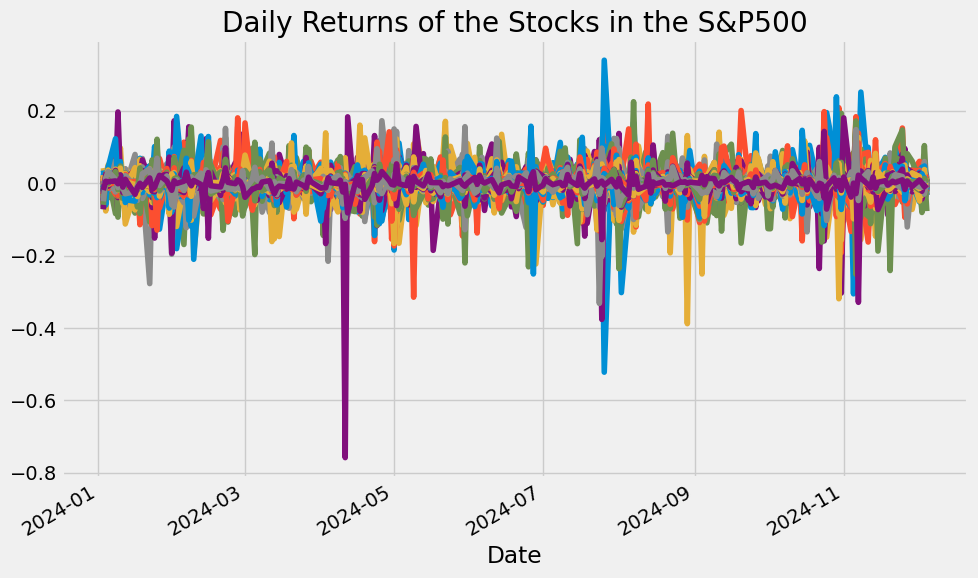

In [ ]:
rs.plot(legend=0, figsize=(10,6), grid=True, title='Daily Returns of the Stocks in the S&P500')
plt.tight_layout()
plt.savefig('tmp1.png')

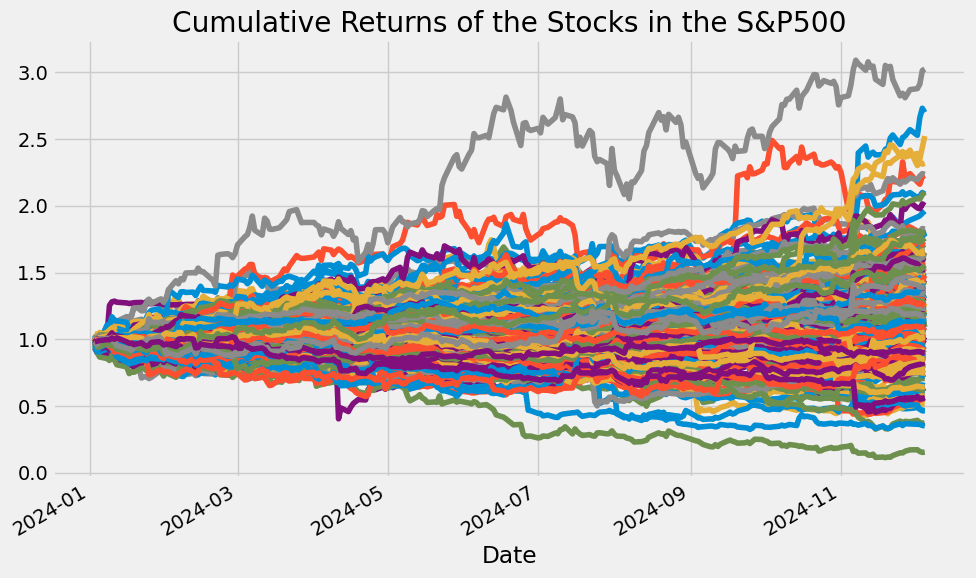

In [ ]:
(rs.cumsum().apply(np.exp)).plot(legend=0, figsize=(10,6), grid=True, title='Cumulative Returns of the Stocks in the S&P500')
plt.tight_layout()
plt.savefig('tmp2.png')

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca = PCA(1).fit(rs.fillna(0))

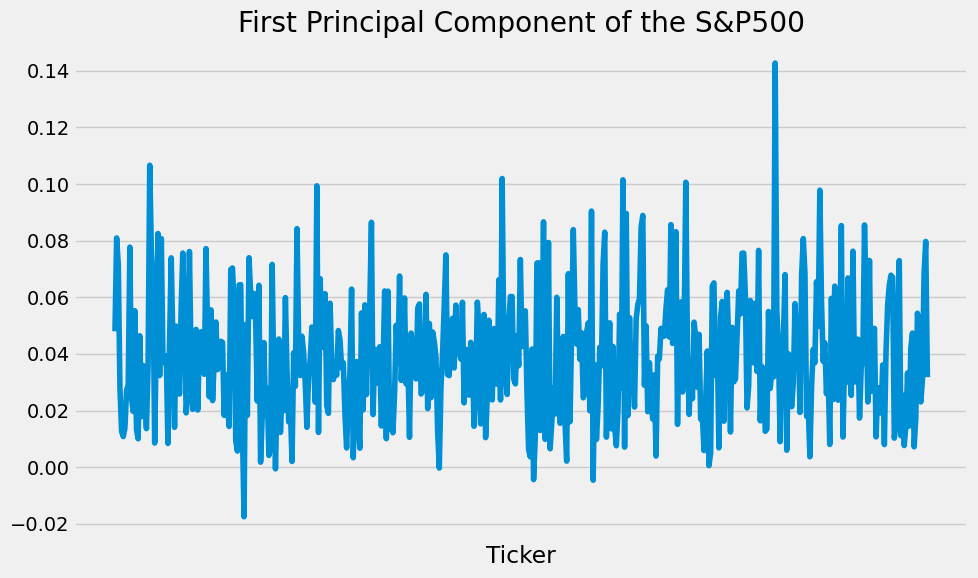

In [ ]:
pc1 = pd.Series(index=rs.columns, data=pca.components_[0])

pc1.plot(figsize=(10,6), xticks=[], grid=True, title='First Principal Component of the S&P500')
plt.tight_layout()
plt.savefig('tmp3.png')

<Axes: xlabel='Date'>

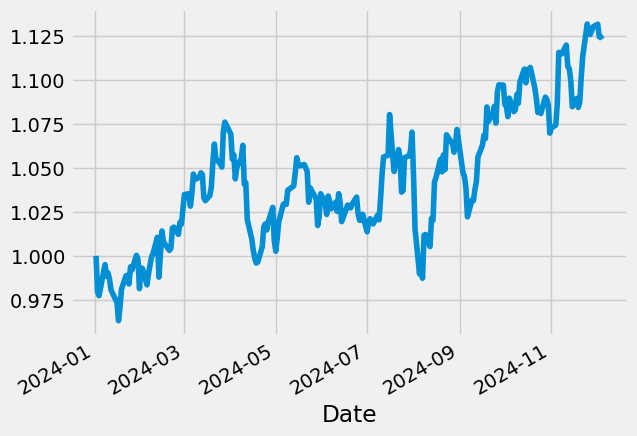

In [ ]:
weights = abs(pc1)/sum(abs(pc1))
myrs = (weights*rs).sum(1)
myrs.cumsum().apply(np.exp).plot()

In [ ]:
prices = yf.download(['SPY'], start='2024-01-01')['Adj Close']

[*********************100%***********************]  1 of 1 completed


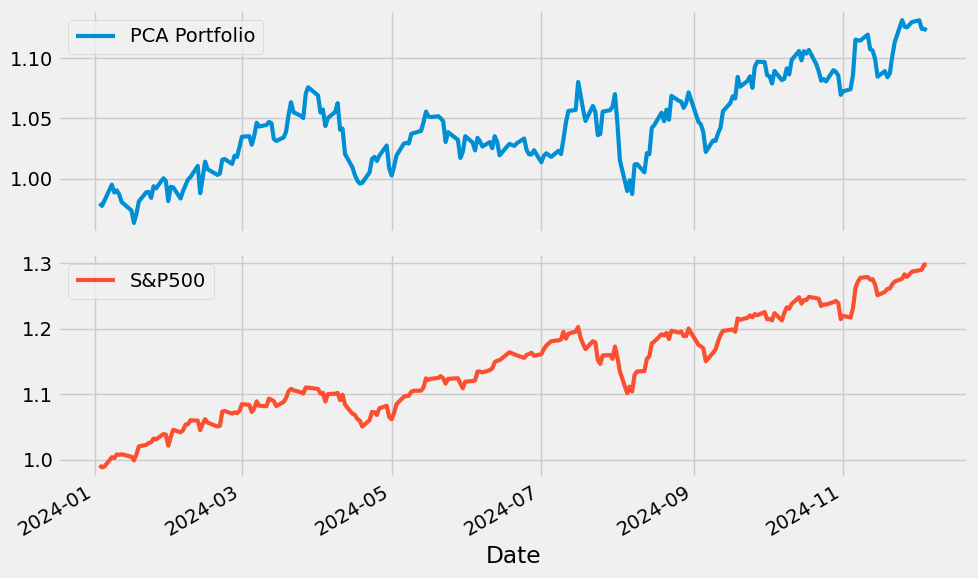

In [ ]:
rs_df = pd.concat([myrs, prices.apply(np.log).diff(1)], axis=1)
rs_df.columns = ["PCA Portfolio", "S&P500"]

rs_df.dropna().cumsum().apply(np.exp).plot(subplots=True, figsize=(10,6), grid=True, linewidth=3);
plt.tight_layout()
plt.savefig('tmp4.png')

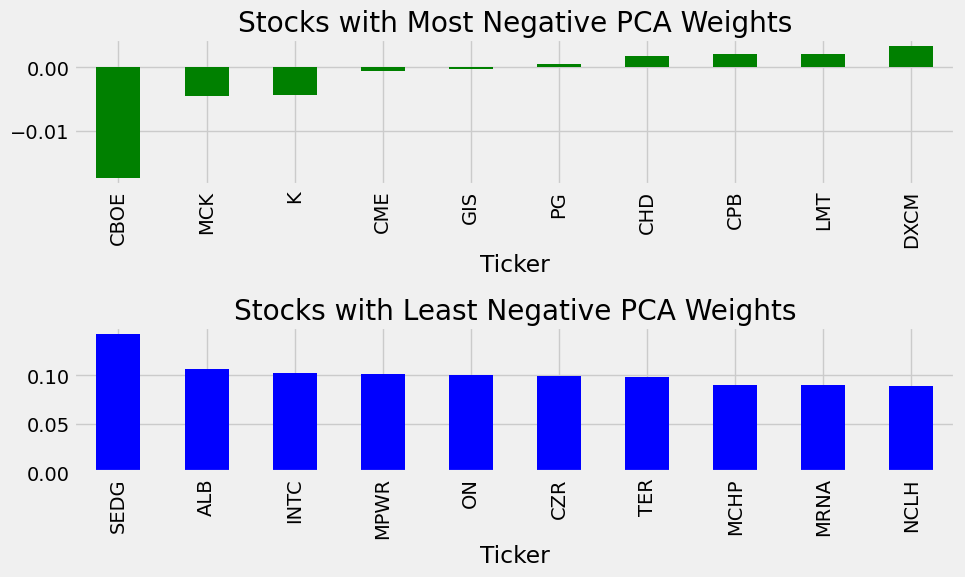

In [ ]:
fig, ax = plt.subplots(2,1, figsize=(10,6))
pc1.nsmallest(10).plot.bar(ax=ax[0], color='green', grid=True, title='Stocks with Most Negative PCA Weights')
pc1.nlargest(10).plot.bar(ax=ax[1], color='blue', grid=True, title='Stocks with Least Negative PCA Weights')

plt.tight_layout()
plt.savefig('tmp5.png')

Dus niet beleggen in (top 5):<br>
Beurs van Chicago (CBOE), McKesson Corporation (MCK), Kellanova (K = Kellogs Cornflakes!), CME Group Inc. (Chicago Mercantile Exchange) en General Mills Inc. (GIS).
<p>
Kopen:<br>
SolarEdge (SEDG), Albemarle Corporation (ALB), Intel (INTC), Monolithic Power Systems, Inc. (MPWR) en ON Semiconductor Corporation (ON).
<p>
<b>NB: Klopt deze conclusie bij deze grafiek? Zijn de aandelen die (qua gewicht) het meest bijdragen aan de eerste PCA-voorspelcomponent van de S&P ook de beste?</b>

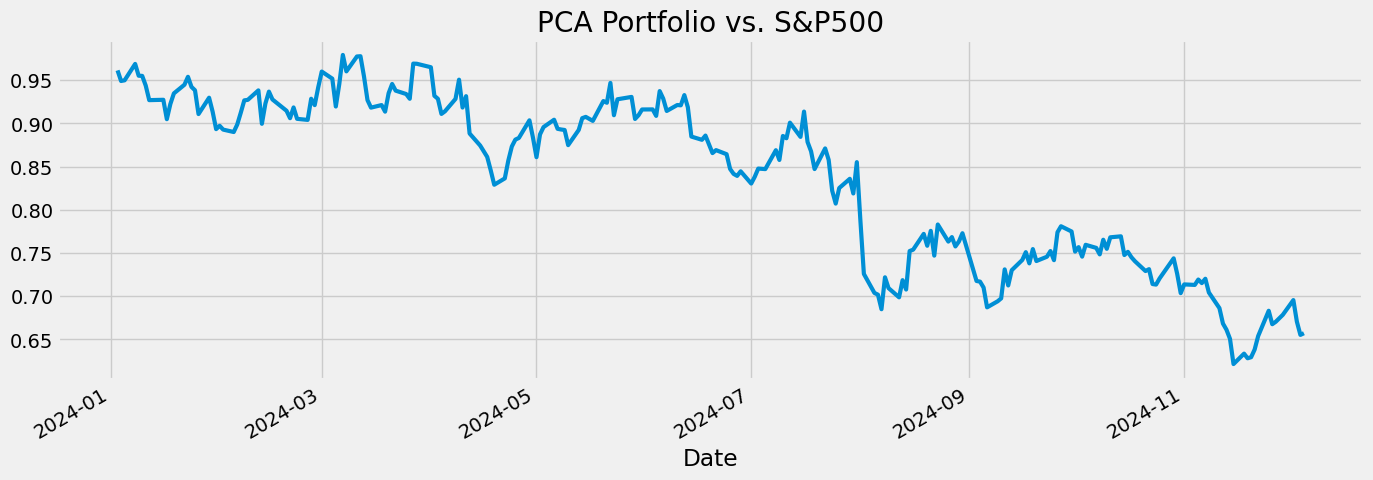

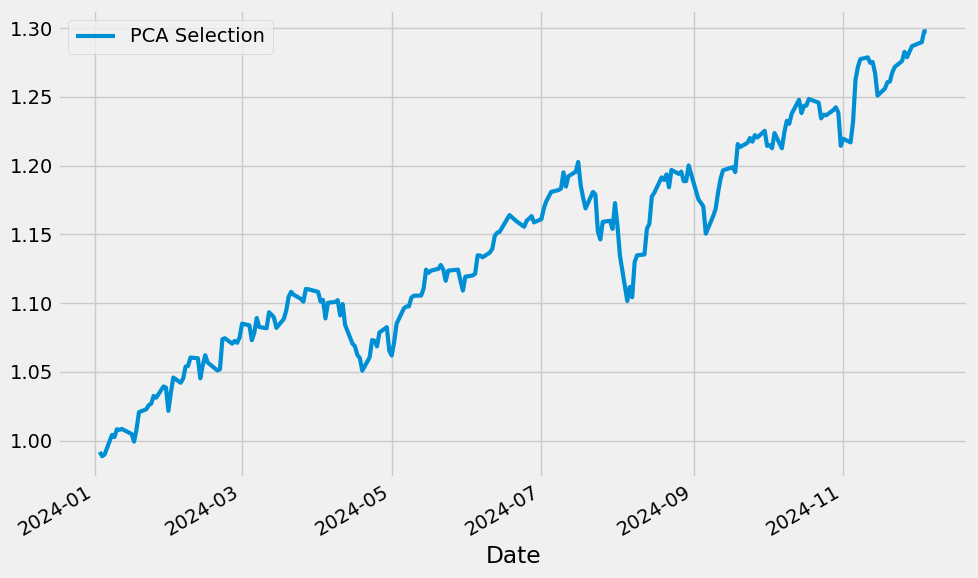

In [ ]:
# ws = [-1,]*10+[1,]*10
# myrs = (rs[list(pc1.nsmallest(10).index)+list(pc1.nlargest(10).index)]*ws).mean(1)
myrs = rs[pc1.nlargest(10).index].mean(1)
myrs.cumsum().apply(np.exp).plot(figsize=(15,5), grid=True, linewidth=3, title='PCA Portfolio vs. S&P500')
prices['2024':].apply(np.log).diff(1).cumsum().apply(np.exp).plot(figsize=(10,6), grid=True, linewidth=3)
plt.legend(['PCA Selection', 'S&P500'])

plt.tight_layout()
plt.savefig('tmp6.png')

Als je dus kiest op basis van de PCA-componenten met positieve gewichten, gaat je grafiek (= rendement?) omlaag in plaats van (zie de S&P) omhoog?